# Praktikum Data Mining — Langkah Pengerjaan (Bagian 4)
**Evaluasi Model Klasifikasi: Confusion Matrix, Accuracy, Precision, Recall dan F1-Score**
**Studi kasus: Prediksi Banjir (dataset Flood Risk in India)**

Nama: AUDITYA MEROSYA PUTRI | NIM: 24343001 

Nama: Muhammad Zahran       | NIM: 24343077

Nama: Muhammad Riyad Anwari | NIM: 24343044

Alur: muat dataset → pisahkan data latih/uji → latih Decision Tree → prediksi → confusion matrix → hitung metrik → interpretasi → eksperimen. Kelas positif adalah **banjir (1)**. File `flood_risk_dataset_india.csv` harus berada satu folder dengan notebook ini. Di bawah setiap sel kode terdapat **Analisis** berdasarkan output hasil eksekusi.

## 4.1 Menyiapkan Dataset

In [10]:
import numpy as np
import pandas as pd

# File dataset harus berada di folder yang sama dengan notebook ini
df = pd.read_csv('flood_risk_dataset_india.csv')
pd.set_option('display.width', 100)   # lebar tampilan agar tabel tidak terpotong

print('Lima baris awal (ditranspos agar muat):')
print(df.head().round(1).T)
print('\nJumlah baris, kolom:', df.shape)
print('Total nilai kosong:', df.isna().sum().sum())
print('\nDistribusi kelas (Flood Occurred):')
print(df['Flood Occurred'].value_counts())
print('Proporsi banjir:', round(df['Flood Occurred'].mean(), 4))

Lima baris awal (ditranspos agar muat):
                                 0       1             2       3             4
Latitude                      18.9    35.6          29.2    25.4          12.5
Longitude                     78.8    77.7          73.1    85.6          81.8
Rainfall (mm)                219.0    55.4         104.0   199.0         144.6
Temperature (°C)              34.1    28.8          43.9    21.6          32.6
Humidity (%)                  43.9    27.6          30.1    34.5          36.3
River Discharge (m³/s)      4236.2  2472.6         977.3  3683.2        2093.4
Water Level (m)                7.4     8.8           4.6     2.9           3.2
Elevation (m)                377.5  7330.6        2205.9  2512.3        2001.8
Land Cover              Water Body  Forest  Agricultural  Desert  Agricultural
Soil Type                     Clay    Peat          Loam   Sandy          Loam
Population Density          7276.7  6897.7        4361.5  6163.1        6168.0
Infrastructu

**Analisis**

- Dataset berisi **10.000 baris** dan 14 kolom (13 fitur dan 1 label `Flood Occurred`). Tidak ada nilai kosong, sehingga tidak diperlukan imputasi.
- Fitur terdiri atas koordinat (`Latitude`, `Longitude`), cuaca (`Rainfall`, `Temperature`, `Humidity`), hidrologi (`River Discharge`, `Water Level`, `Elevation`), lahan (`Land Cover`, `Soil Type`), serta `Population Density`, `Infrastructure`, dan `Historical Floods`.
- Distribusi kelas: **5.057 banjir (50,57%)** dan **4.943 tidak banjir (49,43%)**. Dataset ini **hampir seimbang**, berbeda dengan studi kasus fraud yang sangat tidak seimbang. Konsekuensinya akan terlihat pada eksperimen baseline (4.7).
- Kelas positif adalah banjir (1). Maka **FN** = banjir yang tidak terdeteksi, dan **FP** = alarm banjir palsu.

In [11]:
# Land Cover dan Soil Type berupa teks -> diubah menjadi kolom 0/1 (one-hot encoding)
X = pd.get_dummies(df.drop(columns='Flood Occurred'),
                   columns=['Land Cover', 'Soil Type'], dtype=int)
y = df['Flood Occurred']

print('Jumlah fitur setelah encoding:', X.shape[1])
print(list(X.columns))

Jumlah fitur setelah encoding: 21
['Latitude', 'Longitude', 'Rainfall (mm)', 'Temperature (°C)', 'Humidity (%)', 'River Discharge (m³/s)', 'Water Level (m)', 'Elevation (m)', 'Population Density', 'Infrastructure', 'Historical Floods', 'Land Cover_Agricultural', 'Land Cover_Desert', 'Land Cover_Forest', 'Land Cover_Urban', 'Land Cover_Water Body', 'Soil Type_Clay', 'Soil Type_Loam', 'Soil Type_Peat', 'Soil Type_Sandy', 'Soil Type_Silt']


**Analisis**

- `Land Cover` dan `Soil Type` bertipe teks (masing-masing 5 kategori), sedangkan `DecisionTreeClassifier` di scikit-learn hanya menerima angka. Karena itu keduanya diubah dengan *one-hot encoding* menjadi 10 kolom 0/1.
- Jumlah fitur menjadi **21** (11 fitur numerik/biner asli + 10 kolom hasil encoding). Label `Flood Occurred` dipisahkan ke variabel `y`.

## 4.2 Membagi Data dan Melatih Model

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('Data latih:', len(y_train), '| Data uji:', len(y_test))
print('Distribusi data latih:', y_train.value_counts().to_dict())
print('Distribusi data uji:', y_test.value_counts().to_dict())

Data latih: 7000 | Data uji: 3000
Distribusi data latih: {1: 3540, 0: 3460}
Distribusi data uji: {1: 1517, 0: 1483}


**Analisis**

- Data dibagi 70:30, yaitu **7.000 data latih** dan **3.000 data uji**. Berkat `stratify=y`, proporsi kelas terjaga: data uji berisi 1.517 banjir dan 1.483 tidak banjir.
- Data uji yang besar (3.000) membuat metrik lebih stabil dibanding kasus fraud (yang hanya 5 kasus positif di data uji).
- Karena kelas hampir seimbang, `class_weight='balanced'` hampir tidak mengubah bobot antarkelas. `max_depth=4` membatasi kompleksitas pohon agar tidak overfitting.

## 4.3 Menghitung Confusion Matrix

In [13]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

Confusion matrix:
 [[536 947]
 [521 996]]
TP=996, TN=536, FP=947, FN=521


**Analisis**

Hasil: **TP = 996, TN = 536, FP = 947, FN = 521** (total 3.000).

- Dari 1.517 banjir aktual, model mendeteksi **996** (TP) dan melewatkan **521** (FN).
- Dari 1.483 kejadian tidak banjir, **536** dikenali benar (TN) dan **947** salah diberi alarm banjir (FP).
- Prediksi benar (TP+TN = 1.532) hanya sedikit lebih banyak daripada prediksi salah (FP+FN = 1.468), tanda awal bahwa model tidak jauh lebih baik daripada menebak.
- Nilai ini dibaca dari output kode, bukan dari contoh manual di modul.

## 4.4 Perhitungan Manual dan Verifikasi

In [14]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
print(f'Manual       -> Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print('scikit-learn ->', round(accuracy_score(y_test, y_pred), 3),
      round(precision_score(y_test, y_pred, zero_division=0), 3),
      round(recall_score(y_test, y_pred, zero_division=0), 3),
      round(f1_score(y_test, y_pred, zero_division=0), 3))

Manual       -> Accuracy=0.511; Precision=0.513; Recall=0.657; F1=0.576
scikit-learn -> 0.511 0.513 0.657 0.576


**Analisis**

| Metrik | Perhitungan | Hasil |
|---|---|---|
| Accuracy | (996+536)/3000 | 0,511 (51,1%) |
| Precision | 996/(996+947) | 0,513 (51,3%) |
| Recall | 996/(996+521) | 0,657 (65,7%) |
| F1-score | 2×0,513×0,657/(0,513+0,657) | 0,576 |

- Perhitungan manual dan fungsi scikit-learn **menghasilkan nilai yang sama**, sehingga rumus dan pembacaan confusion matrix sudah benar.
- Accuracy **51,1% hampir sama dengan tebakan acak (50%)**. Recall (65,7%) lebih tinggi daripada precision (51,3%) karena model cenderung memprediksi banjir: 1.943 dari 3.000 data (64,8%) diprediksi banjir.
- Precision 51,3% nyaris sama dengan proporsi banjir di data uji (50,6%), artinya peluang sebuah alarm benar-benar banjir hampir tidak lebih baik daripada menebak.

## 4.5 Visualisasi Confusion Matrix

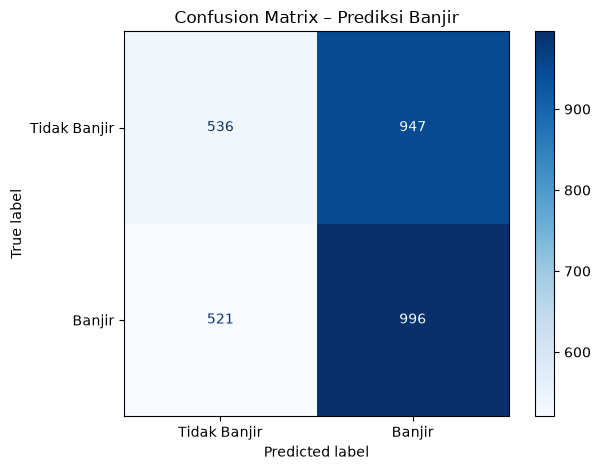

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Tidak Banjir', 'Banjir']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Prediksi Banjir')
plt.tight_layout()
plt.show()

**Analisis (Gambar 1)**

- **Sel FN (kiri-bawah, = 521):** banjir aktual yang diprediksi tidak banjir, yaitu banjir tanpa peringatan dini. Ini kesalahan paling berbahaya karena berisiko menimbulkan korban dan kerugian. Sebanyak 34,3% banjir aktual (521/1.517) terlewat.
- **Sel FP (kanan-atas, = 947):** kejadian tidak banjir yang diberi alarm banjir. Konsekuensinya evakuasi dan kesiagaan yang tidak perlu serta turunnya kepercayaan masyarakat pada peringatan. Sebanyak 63,9% kejadian tidak banjir (947/1.483) terkena alarm palsu.
- Keempat sel berisi angka yang berdekatan (521–996), berbeda dengan kasus fraud yang didominasi satu sel. Pola ini khas model yang tidak mampu membedakan kedua kelas dengan baik.

## 4.6 Interpretasi dan Studi Kasus

**Analisis**

- Dalam prediksi banjir, **FN** (banjir tidak terdeteksi) berisiko menimbulkan korban dan kerugian langsung, sedangkan **FP** (alarm palsu) menimbulkan biaya kesiagaan dan menurunkan kepercayaan publik. Pada sistem peringatan dini, FN umumnya dianggap lebih mahal.
- Model ini memiliki **FN = 521 dan FP = 947**: recall cukup tinggi (65,7%) tetapi dicapai dengan banyak alarm palsu, dan precision hanya 51,3%. Secara keseluruhan model hanya sedikit lebih baik daripada tebakan.
- Pemeriksaan tambahan di bagian 4.9 menunjukkan bahwa penyebabnya kemungkinan besar ada pada **dataset**, bukan pada pilihan model: fitur-fitur di dataset ini hampir tidak berhubungan dengan label banjir.
- Pemilihan metrik harus mengikuti biaya kesalahan: bila FN jauh lebih mahal, recall menjadi prioritas, dengan konsekuensi alarm palsu bertambah.

## 4.7 Eksperimen: Baseline Semua Tidak Banjir

In [16]:
baseline = np.zeros(len(y_test), dtype=int)
from sklearn.metrics import classification_report
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print('Baseline (semua tidak banjir):')
print(classification_report(y_test, baseline, labels=[0, 1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

Baseline accuracy: 0.49433333333333335
Baseline (semua tidak banjir):
              precision    recall  f1-score   support

           0       0.49      1.00      0.66      1483
           1       0.00      0.00      0.00      1517

    accuracy                           0.49      3000
   macro avg       0.25      0.50      0.33      3000
weighted avg       0.24      0.49      0.33      3000

Decision Tree:
              precision    recall  f1-score   support

           0       0.51      0.36      0.42      1483
           1       0.51      0.66      0.58      1517

    accuracy                           0.51      3000
   macro avg       0.51      0.51      0.50      3000
weighted avg       0.51      0.51      0.50      3000



**Analisis**

| Model | Accuracy | Precision banjir | Recall banjir | F1 banjir |
|---|---|---|---|---|
| Baseline (semua tidak banjir) | **0,494** | 0,00 | **0,00** | 0,00 |
| Decision Tree | 0,511 | 0,51 | **0,66** | 0,58 |

- Baseline mencapai accuracy **49,4%**. Berbeda dengan kasus fraud (baseline 96,7%), pada dataset yang hampir seimbang ini accuracy baseline **tidak tinggi**, karena kelas mayoritas hanya sekitar 50%.
- Decision Tree hanya unggul **1,7 poin persentase** dalam accuracy (51,1% vs 49,4%), selisih yang kecil.
- Baseline tidak mendeteksi banjir sama sekali (**recall banjir = 0**), sedangkan Decision Tree mendeteksi 65,7%. Namun precision 51% hampir sama dengan proporsi banjir (50,6%), sehingga alarmnya tidak lebih informatif daripada menebak.
- Pelajaran: accuracy menyesatkan terutama bila kelas tidak seimbang. Pada data seimbang accuracy lebih jujur, tetapi recall dan precision tetap perlu dibaca per kelas.

## 4.8 Eksperimen: Pengaruh Ambang Prediksi

In [17]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
print('Nilai probabilitas unik:', np.unique(y_prob).round(3))
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    print(threshold, 'precision=', round(precision_score(y_test, pred, zero_division=0), 3),
          'recall=', round(recall_score(y_test, pred, zero_division=0), 3))

Nilai probabilitas unik: [0.231 0.349 0.438 0.468 0.505 0.54  0.658 0.678 0.847 1.   ]
0.2 precision= 0.506 recall= 1.0
0.4 precision= 0.506 recall= 0.989
0.5 precision= 0.513 recall= 0.657
0.7 precision= 0.5 recall= 0.003


**Analisis**

| Threshold | Precision | Recall |
|---|---|---|
| 0,2 | 0,506 | 1,000 |
| 0,4 | 0,506 | 0,989 |
| 0,5 | 0,513 | 0,657 |
| 0,7 | 0,500 | 0,003 |

- Menurunkan threshold **menaikkan recall**: dari 0,657 (threshold 0,5) menjadi 0,989 (0,4) dan 1,000 (0,2). Menaikkannya ke 0,7 menjatuhkan recall menjadi 0,003.
- **Precision hampir tidak berubah** (0,500–0,513), selalu sekitar proporsi banjir (50,6%). Artinya recall naik bukan karena model lebih pandai, melainkan karena model memprediksi lebih banyak data sebagai banjir.
- Probabilitas terendah yang dihasilkan pohon adalah 0,231, sehingga pada threshold 0,2 **semua data diprediksi banjir** (recall 1,000 tetapi FP = 1.483). Pada threshold 0,7 hanya 10 dari 3.000 data yang diprediksi banjir.
- Pola precision tidak monoton (0,506 → 0,506 → 0,513 → 0,500). Kesimpulan harus berdasarkan output nyata, bukan asumsi.

## 4.9 Catatan Tambahan: Seberapa Informatif Fitur Dataset Ini?


In [18]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

print('ROC-AUC Decision Tree (data uji):', round(roc_auc_score(y_test, y_prob), 3))
rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
auc_rf = cross_val_score(rf, X, y, cv=5, scoring='roc_auc')
print('ROC-AUC Random Forest (5-fold CV):', auc_rf.round(3), '| rata-rata =', round(auc_rf.mean(), 3))
korelasi = X.assign(y=y).corr()['y'].drop('y').abs().sort_values(ascending=False)
print('\nKorelasi absolut terbesar antara fitur dan label:')
print(korelasi.head(3).round(3))

ROC-AUC Decision Tree (data uji): 0.509
ROC-AUC Random Forest (5-fold CV): [0.519 0.514 0.505 0.516 0.517] | rata-rata = 0.514

Korelasi absolut terbesar antara fitur dan label:
Humidity (%)             0.028
Land Cover_Water Body    0.026
Temperature (°C)         0.016
Name: y, dtype: float64


ROC-AUC Random Forest (5-fold CV): [0.519 0.514 0.505 0.516 0.517] | rata-rata = 0.514

Korelasi absolut terbesar antara fitur dan label:
Humidity (%)             0.028
Land Cover_Water Body    0.026
Temperature (°C)         0.016
Name: y, dtype: float64


**Analisis**

- ROC-AUC Decision Tree pada data uji sebesar **0,509**. Nilai 0,5 berarti tidak lebih baik daripada tebakan acak, dan 1,0 berarti sempurna.
- Random Forest (model yang lebih kuat) dengan validasi silang 5-lipat juga hanya memperoleh ROC-AUC rata-rata sekitar **0,51**. Jadi masalahnya bukan pada Decision Tree.
- Korelasi absolut tertinggi antara satu fitur dan label hanya sekitar **0,03**, yang praktis nol.
- **Kesimpulan:** dataset ini hampir tidak mengandung sinyal yang dapat dipelajari, sehingga model apa pun akan berkinerja mendekati tebakan. Untuk tujuan praktikum, hal ini tetap memadai karena yang dinilai adalah cara menghitung dan menginterpretasikan metrik. Namun hasilnya **tidak boleh dipakai untuk menyimpulkan bahwa model layak memprediksi banjir**.